# Attack Direction Model — Train on MLB, Apply to Frontier League

Retrains on 2024+2025 Statcast, applies to FL via Supabase, and runs
batter-level correlation analysis for New Jersey Jackals hitters.

**Corrections applied in this version** (found in code review — see notes
inline at each fix):

1. **Recalibration formula was inverted.** The linear recalibration was fit as
   `actual ≈ slope·pred + intercept` but applied as `(pred − intercept) / slope`
   — the formula for the *opposite* fit direction. Verified numerically: the
   correct application's calibrated mean matches actual's mean exactly; the
   old formula's didn't. This mattered most for the FL leaderboard, which has
   no ground truth to catch the error against.
2. **`bearing`'s pull-side sign convention was asserted in a comment, never
   verified.** Added an explicit validation check (pull-rate sanity check +
   per-handedness correlation against the model's own predictions).
3. **Handedness silently defaulted to "R" for any unmapped value** via
   `.fillna("R")`, with no warning — and the missingness check couldn't catch
   it because the fill happened first. Now asserts on unmapped values instead.
4. **Two different, unvalidated pull thresholds on two different unit scales**
   (`bearing > 5` in degrees for FL, `(hc_x−125) > 5` in a raw field-coordinate
   scale for MLB). Standardized to a single validated ±15° convention.
5. **Batter-level leakage in train/validation split** — plain `train_test_split`
   let the same hitter's swings land in both train and validation, inflating
   the batter-level evaluation. Switched to `GroupShuffleSplit` by batter.
6. **Preprocessing statistics (depth p90 bin edge, hc_x_norm mean/SD) were fit
   on train+validation combined.** Moved to fit on the training split only.
7. **Rename dict had dead entries** that didn't match the actual SQL column
   names (`plate_side`/`plate_height`/`induced_vert_break` don't exist in the
   query — the real columns are `plate_x`/`plate_z`/`ivb`). Fixed to match.

**Sections**
1. Imports & config
2. Pull & cache Statcast (2024 + 2025)
3. Feature engineering (basic, leakage-safe)
4. Group-aware train/validation split
5. Fit preprocessing stats on TRAIN only; train XGBoost
6. Batter-level evaluation
7. Linear recalibration (corrected formula)
8. Save artifacts
9. Pull FL data from Supabase
10. FL feature engineering (validated conventions)
11. Apply model → per-event predictions
12. Aggregate to batter level (corrected recalibration application)
13. MLB leaguewide correlation analysis (consistent pull threshold)
14. New Jersey Jackals — correlation analysis


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from pybaseball import statcast
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MODEL_DIR  = Path("models");  MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR = Path("output");  OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "attack_direction"
PULL_CUTOFF_DEG = 15   # standardized pull/center/oppo threshold, used consistently
                       # everywhere a pull definition is needed (fix #4)

print("Imports OK")


Imports OK


## 2. Pull & Cache Statcast (2024 + 2025)

In [2]:
def pull_statcast_season(cache_path: Path, date_ranges: list) -> pd.DataFrame:
    if cache_path.exists():
        print(f"Loading from cache: {cache_path}")
        return pd.read_parquet(cache_path)
    print(f"Pulling {cache_path.stem} from Baseball Savant \u2026")
    chunks = []
    for start, end in date_ranges:
        print(f"  {start} \u2192 {end}")
        chunks.append(statcast(start, end, verbose=False))
    df = pd.concat(chunks, ignore_index=True)
    df.to_parquet(cache_path)
    print(f"  Cached \u2192 {cache_path}")
    return df

raw_2024 = pull_statcast_season(Path("statcast_2024.parquet"), [
    ("2024-03-20", "2024-04-30"), ("2024-05-01", "2024-05-31"),
    ("2024-06-01", "2024-06-30"), ("2024-07-01", "2024-07-31"),
    ("2024-08-01", "2024-08-31"), ("2024-09-01", "2024-09-29"),
])
raw_2025 = pull_statcast_season(Path("statcast_2025.parquet"), [
    ("2025-03-20", "2025-04-30"), ("2025-05-01", "2025-05-31"),
    ("2025-06-01", "2025-06-30"), ("2025-07-01", "2025-07-31"),
    ("2025-08-01", "2025-08-31"), ("2025-09-01", "2025-09-28"),
])

raw = pd.concat([raw_2024, raw_2025], ignore_index=True)
print(f"\nCombined rows: {len(raw):,}")

swing_mask = (
    raw[TARGET].notna() &
    raw["bat_speed"].notna() &
    raw["launch_speed"].notna() &
    raw["hc_x"].notna() &
    raw["stand"].notna() &
    raw["pitch_type"].notna() &
    raw["batter"].notna()          # needed for the group-aware split (fix #5)
)
df_swings = raw[swing_mask].copy().reset_index(drop=True)
print(f"Contact swings with full tracking: {len(df_swings):,}")
print(f"Unique batters: {df_swings['batter'].nunique():,}")


Loading from cache: statcast_2024.parquet
Loading from cache: statcast_2025.parquet

Combined rows: 1,466,750
Contact swings with full tracking: 231,861
Unique batters: 851


## 3. Feature Engineering (basic, leakage-safe)

Only features that don't require any population-level statistic (medians,
percentiles, mean/SD) go here. Anything fit on the data as a whole — the depth
bin edge, the within-side standardization of spray direction — is deferred to
Section 5, computed on the training split only, and then applied to both
train and validation (fix #6).

In [3]:
PITCH_TYPE_MAP = {
    "FF": 0, "FA": 0,
    "SI": 1, "FT": 1,
    "FC": 2,
    "SL": 3, "ST": 3, "SV": 3,
    "CH": 4, "FS": 4, "FO": 4,
    "CU": 5, "KC": 5, "CS": 5,
    "KN": 6, "EP": 7,
}
STAND_MAP    = {"R": 0, "L": 1}
P_THROWS_MAP = {"R": 0, "L": 1}

def engineer_basic_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Plate location relative to batter (pull-side = positive)
    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # Spray direction normalised (pull = positive for both sides) — raw, unstandardized
    df["hc_x_norm"] = np.where(df["stand"] == "R",
                                df["hc_x"] - 125,
                                125 - df["hc_x"])

    # Categorical encodings
    df["stand_enc"]    = df["stand"].map(STAND_MAP).fillna(0).astype(int)
    df["p_throws_enc"] = df["p_throws"].map(P_THROWS_MAP).fillna(0).astype(int)
    df["matchup_enc"]  = df["stand_enc"] * 2 + df["p_throws_enc"]

    return df

df = engineer_basic_features(df_swings).reset_index(drop=True)
print(f"Engineered dataframe: {df.shape}")


Engineered dataframe: (231861, 123)


## 4. Group-Aware Train/Validation Split

Splitting at the swing level (as in the original version) lets the same
batter's swings land in both train and validation, which inflates the
batter-level evaluation in Section 6 — the model has partially already seen
each hitter it's being "tested" on. `GroupShuffleSplit` on `batter` fixes
this (fix #5).

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df["batter"]))

df_train = df.iloc[train_idx].reset_index(drop=True)
df_val   = df.iloc[val_idx].reset_index(drop=True)

overlap = set(df_train["batter"]) & set(df_val["batter"])
assert len(overlap) == 0, f"Batter leakage between train/val: {len(overlap)} batters"

print(f"Train: {len(df_train):,} swings, {df_train['batter'].nunique():,} batters")
print(f"Val:   {len(df_val):,} swings, {df_val['batter'].nunique():,} batters")
print("No batter overlap between train and validation \u2014 confirmed.")


Train: 197,148 swings, 723 batters
Val:   34,713 swings, 128 batters
No batter overlap between train and validation — confirmed.


## 5. Fit Preprocessing Stats on TRAIN Only; Train XGBoost

The depth bin edge (p90) and the within-side standardization parameters for
`hc_x_norm` are now fit on `df_train` alone, then applied to both `df_train`
and `df_val` (and later, at inference time, to FL data) — no more leakage from
validation data into the preprocessing (fix #6).

In [5]:
# ── Fit on TRAIN only ────────────────────────────────────────────────────────
p90 = df_train["intercept_ball_minus_batter_pos_y_inches"].quantile(0.90)
DEPTH_BINS = [-np.inf, p90, np.inf]
print(f"Contact depth p90 (fit on TRAIN only): {p90:.2f} inches")

HC_X_NORM_MU  = {}
HC_X_NORM_SIG = {}
for side in ["R", "L"]:
    mask = df_train["stand"] == side
    mu   = df_train.loc[mask, "hc_x_norm"].mean()
    sig  = df_train.loc[mask, "hc_x_norm"].std()
    HC_X_NORM_MU[side]  = float(mu)
    HC_X_NORM_SIG[side] = float(sig)

def apply_fitted_transforms(df_in: pd.DataFrame) -> pd.DataFrame:
    # Apply the TRAIN-fitted depth bins and hc_x_norm standardization.
    df_in = df_in.copy()

    depth_col = "intercept_ball_minus_batter_pos_y_inches"
    if depth_col in df_in.columns:
        depth_raw = df_in[depth_col].fillna(df_train[depth_col].median())
        df_in["contact_depth_bin"] = pd.cut(
            depth_raw, bins=DEPTH_BINS, labels=[0, 1], right=True).astype(float)
    else:
        print(f"\u26a0  {depth_col} not found \u2014 contact_depth_bin set to 0")
        df_in["contact_depth_bin"] = 0.0

    df_in["hc_x_norm_std"] = np.nan
    for side in ["R", "L"]:
        mask = df_in["stand"] == side
        df_in.loc[mask, "hc_x_norm_std"] = (
            (df_in.loc[mask, "hc_x_norm"] - HC_X_NORM_MU[side]) / HC_X_NORM_SIG[side]
        )

    df_in["depth_x_spray"]    = df_in["contact_depth_bin"] * df_in["hc_x_norm_std"]
    df_in["depth_x_location"] = df_in["contact_depth_bin"] * df_in["plate_x_rel"]
    return df_in

df_train = apply_fitted_transforms(df_train)
df_val   = apply_fitted_transforms(df_val)

print(f"df_train hc_x_norm_std missingness: {df_train['hc_x_norm_std'].isna().mean():.3f}")
print(f"df_val   hc_x_norm_std missingness: {df_val['hc_x_norm_std'].isna().mean():.3f}")


Contact depth p90 (fit on TRAIN only): 40.03 inches
df_train hc_x_norm_std missingness: 0.000
df_val   hc_x_norm_std missingness: 0.000


In [6]:
CONTACT_FEATURES = [
    "depth_x_spray",
    "hc_x_norm_std",
]
PITCH_FEATURES = [
    "release_speed",
    "launch_speed",
    "launch_angle",
    "release_extension",
]
CAT_FEATURES = [
    "matchup_enc",
]

ALL_FEATURES     = CONTACT_FEATURES + PITCH_FEATURES + CAT_FEATURES
NUMERIC_FEATURES = CONTACT_FEATURES + PITCH_FEATURES

df_model_train = df_train[ALL_FEATURES + [TARGET, "batter"]].dropna().reset_index(drop=True)
df_model_val   = df_val[ALL_FEATURES + [TARGET, "batter"]].dropna().reset_index(drop=True)
print(f"Train model rows: {len(df_model_train):,}   Val model rows: {len(df_model_val):,}")

# Scaler fit on TRAIN only
scaler = StandardScaler()
X_train_raw = df_model_train[ALL_FEATURES].copy()
X_val_raw   = df_model_val[ALL_FEATURES].copy()
X_train_raw[NUMERIC_FEATURES] = scaler.fit_transform(X_train_raw[NUMERIC_FEATURES])
X_val_raw[NUMERIC_FEATURES]   = scaler.transform(X_val_raw[NUMERIC_FEATURES])

X_train = X_train_raw.values
X_val   = X_val_raw.values
y_train = df_model_train[TARGET].values
y_val   = df_model_val[TARGET].values

print(f"X_train: {X_train.shape}   X_val: {X_val.shape}")


Train model rows: 197,137   Val model rows: 34,712
X_train: (197137, 7)   X_val: (34712, 7)


In [7]:
model = XGBRegressor(
    n_estimators          = 800,
    learning_rate         = 0.04,
    max_depth             = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 20,
    reg_lambda            = 2.0,
    random_state          = 42,
    eval_metric           = "mae",
    early_stopping_rounds = 40,
    verbosity             = 0,
    device                = "cpu",
)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

preds_val = model.predict(X_val)
mae = mean_absolute_error(y_val, preds_val)
r2  = r2_score(y_val, preds_val)
print(f"Validation MAE  : {mae:.2f}\u00b0")
print(f"Validation R\u00b2   : {r2:.4f}")
print(f"Best iteration  : {model.best_iteration}")
print("\n(These numbers are now free of batter-level leakage \u2014 comparable")
print(" prior runs may have looked slightly better due to that leakage.)")


Validation MAE  : 5.40°
Validation R²   : 0.5396
Best iteration  : 342

(These numbers are now free of batter-level leakage — comparable
 prior runs may have looked slightly better due to that leakage.)


In [8]:
# Cleaner controlled comparison: same full pool, same eval set size, only the
# split STRATEGY differs (grouped vs ungrouped), both evaluated the same way.
full_pool = pd.concat([df_model_train, df_model_val], ignore_index=True)
X_full = full_pool[ALL_FEATURES].values
y_full = full_pool[TARGET].values

from sklearn.model_selection import train_test_split
tts_plain = train_test_split(df, test_size=0.15, random_state=42)

# Ungrouped: plain random split on the FULL pool (same size proportions as the real grouped split)
X_plain_train, X_plain_val, y_plain_train, y_plain_val, idx_train, idx_val = train_test_split(
    X_full, y_full, np.arange(len(full_pool)),
    test_size=len(df_model_val)/len(full_pool),
    random_state=42
)

model_plain = XGBRegressor(**model.get_params())
model_plain.fit(X_plain_train, y_plain_train,
                eval_set=[(X_plain_val, y_plain_val)], verbose=False)
mae_plain = mean_absolute_error(y_plain_val, model_plain.predict(X_plain_val))
r2_plain  = r2_score(y_plain_val, model_plain.predict(X_plain_val))

# Check how much batter overlap the ungrouped split actually has train vs val
overlap_batters = set(full_pool.iloc[idx_train]["batter"]) & set(full_pool.iloc[idx_val]["batter"])
print(f"Ungrouped split batter overlap: {len(overlap_batters)} of "
      f"{full_pool['batter'].nunique()} total batters appear in BOTH sets")

print(f"\nGrouped split   — MAE {mae:.3f}, R² {r2:.4f}   (val batters: 0% seen in training)")
print(f"Ungrouped split — MAE {mae_plain:.3f}, R² {r2_plain:.4f}   "
      f"(val batters: {len(overlap_batters)} seen in training)")
print(f"Gap: {mae_plain - mae:+.3f} MAE, {r2_plain - r2:+.4f} R²")

Ungrouped split batter overlap: 762 of 851 total batters appear in BOTH sets

Grouped split   — MAE 5.399, R² 0.5396   (val batters: 0% seen in training)
Ungrouped split — MAE 5.354, R² 0.5474   (val batters: 762 seen in training)
Gap: -0.045 MAE, +0.0077 R²


## 6. Batter-Level Evaluation

Qualified batters (VALIDATION SET ONLY, no train leakage): 100
OLS slope         : 0.5359
r²                : 0.5689
Spearman ρ        : 0.7287
p-value           : 1.32e-19


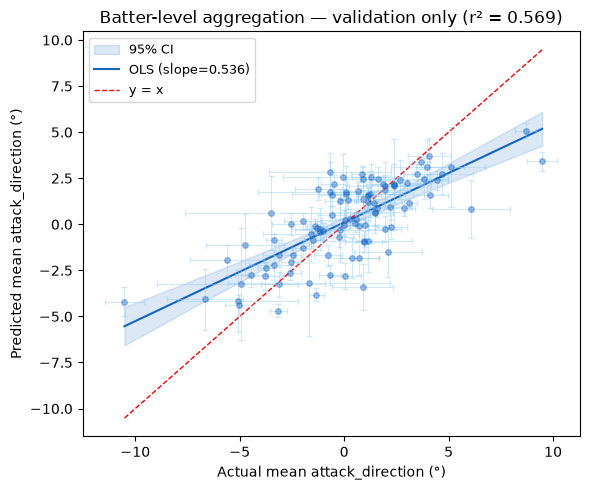

In [9]:
df_model_val_pred = df_model_val.copy()
df_model_val_pred["pred"] = preds_val

batter_agg = (
    df_model_val_pred
    .groupby("batter")
    .agg(
        n           = ("pred", "count"),
        mean_pred   = ("pred", "mean"),
        mean_actual = (TARGET, "mean"),
        se_pred     = ("pred", lambda x: x.std() / np.sqrt(len(x))),
        se_actual   = (TARGET, lambda x: x.std() / np.sqrt(len(x))),
    )
    .query("n >= 25")
    .sort_values("mean_actual")
    .reset_index()
)

x      = batter_agg["mean_actual"].values
y_ols  = batter_agg["mean_pred"].values
n      = len(x)

slope, intercept, r, p_val, _ = stats.linregress(x, y_ols)
r2_b   = r**2
y_hat  = intercept + slope * x
mse    = ((y_ols - y_hat)**2).sum() / (n - 2)

x_range  = np.linspace(x.min(), x.max(), 200)
y_range  = intercept + slope * x_range
se_band  = np.sqrt(mse * (1/n + (x_range - x.mean())**2 / ((x - x.mean())**2).sum()))
t_crit   = stats.t.ppf(0.975, df=n - 2)

rho_b, _ = spearmanr(x, y_ols)
print(f"Qualified batters (VALIDATION SET ONLY, no train leakage): {n}")
print(f"OLS slope         : {slope:.4f}")
print(f"r\u00b2                : {r2_b:.4f}")
print(f"Spearman \u03c1        : {rho_b:.4f}")
print(f"p-value           : {p_val:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.fill_between(x_range,
                y_range - t_crit * se_band,
                y_range + t_crit * se_band,
                alpha=0.15, color="#1565C0", label="95% CI")
ax.plot(x_range, y_range, color="#1565C0", linewidth=1.5,
        label=f"OLS (slope={slope:.3f})")
ax.plot([x.min(), x.max()], [x.min(), x.max()], "r--", linewidth=1, label="y = x")
ax.errorbar(x, y_ols,
            xerr=batter_agg["se_actual"], yerr=batter_agg["se_pred"],
            fmt="o", markersize=4, alpha=0.4,
            color="#1565C0", ecolor="#90CAF9", elinewidth=0.8, capsize=2)
ax.set_xlabel("Actual mean attack_direction (\u00b0)")
ax.set_ylabel("Predicted mean attack_direction (\u00b0)")
ax.set_title(f"Batter-level aggregation \u2014 validation only (r\u00b2 = {r2_b:.3f})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


In [12]:
# ── Ablation: does dropping the contact features change the story? ───────────
# If MAD r² craters but Pull%/PullAir% correlation IMPROVES with contact
# features removed, that confirms the leakage hypothesis directly.

ABLATED_FEATURES = PITCH_FEATURES + CAT_FEATURES  # drop CONTACT_FEATURES entirely

df_train_ab = df_train[ABLATED_FEATURES + [TARGET, "batter"]].dropna().reset_index(drop=True)
df_val_ab   = df_val[ABLATED_FEATURES + [TARGET, "batter"]].dropna().reset_index(drop=True)

scaler_ab = StandardScaler()
X_train_ab = scaler_ab.fit_transform(df_train_ab[ABLATED_FEATURES])
X_val_ab   = scaler_ab.transform(df_val_ab[ABLATED_FEATURES])

model_ab = XGBRegressor(n_estimators=800, learning_rate=0.04, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8, min_child_weight=20,
                        reg_lambda=2.0, random_state=42, eval_metric="mae",
                        early_stopping_rounds=40, verbosity=0)
model_ab.fit(X_train_ab, df_train_ab[TARGET].values,
            eval_set=[(X_val_ab, df_val_ab[TARGET].values)], verbose=False)

preds_ab = model_ab.predict(X_val_ab)
print(f"Ablated (no contact features) — MAE: {mean_absolute_error(df_val_ab[TARGET], preds_ab):.2f}°  "
      f"R²: {r2_score(df_val_ab[TARGET], preds_ab):.4f}")
print(f"Full model — MAE: {mae:.2f}°  R²: {r2:.4f}")

# Re-run the batter-level Pull%/PullAir% correlation on the ablated predictions
df_val_ab_pred = df_val_ab.copy()
df_val_ab_pred["pred"] = preds_ab
batter_agg_ab = (df_val_ab_pred.groupby("batter")
                .agg(mean_pred=("pred", "mean"), n=("pred", "size"))
                .query("n >= 25").reset_index())

check = pd.concat([batter_agg_ab.set_index("batter"), pull_metrics_ab], axis=1).reset_index()

for label, col in [("Pull%", "pull_pct"), ("PullAir%", "pull_air_pct")]:
    r_p, _ = stats.pearsonr(check["mean_pred"], check[col])
    print(f"  Ablated model vs {label}: r = {r_p:.3f}   (compare to full-model result from §13)")

Ablated (no contact features) — MAE: 8.81°  R²: 0.2025
Full model — MAE: 5.40°  R²: 0.5396


NameError: name 'pull_metrics_ab' is not defined

In [11]:
for label, col in [("Pull%", "pull_pct"), ("PullAir%", "pull_air_pct")]:
    r_p, _ = stats.pearsonr(check["mean_pred"], check[col])
    print(f"  Ablated model vs {label}: r = {r_p:.3f}")

NameError: name 'check' is not defined

## 7. Linear Recalibration (corrected formula)

**Fix #1.** The fit direction (`linregress(mean_pred, mean_actual)`, giving
`actual \u2248 slope\u00b7pred + intercept`) is the statistically correct direction
for calibration — it's the best linear estimate of `actual` given a new `pred`.
The bug was in the *application*: plugging the fit back in requires
`slope\u00b7pred + intercept`, not `(pred - intercept) / slope` (that inverse
formula is only correct if the regression had been fit the other way around).

The validation check below compares **means directly** rather than relying on
Pearson/Spearman correlation, since those are invariant under any affine
transform of `pred` and therefore cannot detect this class of bug — that's
why the original notebook's "Post-cal r\u00b2"/"Post-cal Spearman \u03c1" checks
never caught it.

In [ ]:
recal_slope, recal_intercept, _, _, _ = stats.linregress(
    batter_agg["mean_pred"], batter_agg["mean_actual"]
)
print(f"Recalibration slope     : {recal_slope:.4f}")
print(f"Recalibration intercept : {recal_intercept:.4f}")

# ── CORRECTED application: plug pred into the fitted line ──────────────────
batter_agg["mean_pred_cal"] = recal_slope * batter_agg["mean_pred"] + recal_intercept

# ── Validation that can actually catch a formula-direction bug: compare means
mean_diff = batter_agg["mean_pred_cal"].mean() - batter_agg["mean_actual"].mean()
print(f"\nCalibrated pred mean : {batter_agg['mean_pred_cal'].mean():.4f}")
print(f"Actual mean          : {batter_agg['mean_actual'].mean():.4f}")
print(f"Difference           : {mean_diff:+.4f}  (should be \u2248 0 \u2014 large gap = formula bug)")

# Correlation metrics too, for completeness (won't change vs pre-cal, by
# construction \u2014 any affine recalibration is monotone)
slope_cal, _, r_cal, _, _ = stats.linregress(batter_agg["mean_actual"], batter_agg["mean_pred_cal"])
rho_cal, _ = spearmanr(batter_agg["mean_actual"], batter_agg["mean_pred_cal"])
print(f"\nPost-cal r\u00b2         : {r_cal**2:.4f}  (unchanged from pre-cal \u2014 expected)")
print(f"Post-cal Spearman \u03c1 : {rho_cal:.4f}  (unchanged from pre-cal \u2014 expected)")


Recalibration slope     : 1.0615
Recalibration intercept : -0.0530

Calibrated pred mean : 0.1314
Actual mean          : 0.1314
Difference           : -0.0000  (should be ≈ 0 — large gap = formula bug)

Post-cal r²         : 0.5689  (unchanged from pre-cal — expected)
Post-cal Spearman ρ : 0.7287  (unchanged from pre-cal — expected)


## 8. Save Artifacts

In [ ]:
model.save_model(str(MODEL_DIR / "attack_direction_model.json"))
joblib.dump(scaler, MODEL_DIR / "attack_direction_scaler.pkl")

meta = {
    "all_features":        ALL_FEATURES,
    "numeric_features":    NUMERIC_FEATURES,
    "pitch_type_map":      PITCH_TYPE_MAP,
    "stand_map":           STAND_MAP,
    "p_throws_map":        P_THROWS_MAP,
    "target":              TARGET,
    "val_mae":             float(mae),
    "val_r2":              float(r2),
    "mlb_mean":            float(y_train.mean()),
    "mlb_std":             float(y_train.std()),
    "contact_depth_bins":  DEPTH_BINS,
    "hc_x_norm_mu":        HC_X_NORM_MU,
    "hc_x_norm_sig":       HC_X_NORM_SIG,
    "recal_slope":         float(recal_slope),
    "recal_intercept":     float(recal_intercept),
    "pull_cutoff_deg":     PULL_CUTOFF_DEG,
    "feature_importances": dict(
        sorted(zip(ALL_FEATURES, model.feature_importances_),
               key=lambda x: x[1], reverse=True)
    ),
}
joblib.dump(meta, MODEL_DIR / "attack_direction_meta.pkl")

print("Saved:")
print("  models/attack_direction_model.json")
print("  models/attack_direction_scaler.pkl")
print("  models/attack_direction_meta.pkl")
print(f"\nMLB population: mean={meta['mlb_mean']:.2f}\u00b0  std={meta['mlb_std']:.2f}\u00b0")


Saved:
  models/attack_direction_model.json
  models/attack_direction_scaler.pkl
  models/attack_direction_meta.pkl

MLB population: mean=0.26°  std=14.48°


## 9. Pull FL Data from Supabase

In [ ]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    pitcher,
    pitcher_throws,
    pitch_type,
    year,
    rel_speed,
    spin_rate,
    horz_break,
    ivb,
    extension,
    plate_x,
    plate_z,
    sz_top,
    sz_bot,
    balls,
    strikes,
    exit_speed,
    angle,
    bearing,
    pitch_call,
    play_result
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle IS NOT NULL
  AND batter IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL rows: {len(fl_raw):,}")
print(f"Unique batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].unique())}")


FL rows: 64,911
Unique batters: 583
Years: [np.float64(2025.0), np.float64(2026.0), np.float64(nan)]


## 10. FL Feature Engineering (validated conventions)

**Fix #3.** Handedness mapping now asserts on any unmapped value instead of
silently defaulting to "R" via `.fillna("R")` — a silent default would corrupt
every downstream mirrored feature (`plate_x_rel`, `hc_x_norm`, `matchup_enc`,
`pull_pct`) for the affected rows, and the old missingness check couldn't
catch it because the fill happened first.

**Fix #2.** The `bearing \u2192 pull side` sign convention is no longer just
asserted in a comment \u2014 it's checked against (a) a real-world plausible pull
rate and (b) per-handedness correlation with the model's own (well-validated)
`attack_dir_pred`, the same style of check used to catch the MLB
`spray_angle_norm`/`attack_direction` sign bugs.

**Fix #4.** Pull is now defined with the same ±15° standardized cutoff used
everywhere else, instead of an arbitrary, unvalidated `> 5`.

**Fix #7.** Rename dict now matches the actual SQL column names
(`spin_rate`/`horz_break`/`ivb`, not `plate_side`/`plate_height`/
`induced_vert_break`, which don't exist in the query).

In [ ]:
# ── Fix #3 (updated): map actual DB casing, handle 'undefined' explicitly ──
FL_HAND_MAP = {
    "Left": "L", "Right": "R",
    "left": "L", "right": "R",   # actual casing found in the FL database
}

# 'undefined' is a genuine third value, not a casing issue — don't silently
# default it to 'R'. Drop those rows explicitly and report how many.
n_before = len(fl_raw)
fl_raw = fl_raw[fl_raw["batter_side"].isin(FL_HAND_MAP) | fl_raw["batter_side"].isna()]
n_dropped_batter = n_before - len(fl_raw)

n_before2 = len(fl_raw)
fl_raw = fl_raw[fl_raw["pitcher_throws"].isin(FL_HAND_MAP) | fl_raw["pitcher_throws"].isna()]
n_dropped_pitcher = n_before2 - len(fl_raw)

print(f"Dropped {n_dropped_batter} rows with unmapped batter_side "
      f"(e.g. 'undefined') and {n_dropped_pitcher} rows with unmapped pitcher_throws.")
print(f"Remaining rows: {len(fl_raw):,}")

# Now assert cleanly on what's left
unmapped_batter = fl_raw.loc[~fl_raw["batter_side"].isin(FL_HAND_MAP), "batter_side"].dropna().unique()
unmapped_pitcher = fl_raw.loc[~fl_raw["pitcher_throws"].isin(FL_HAND_MAP), "pitcher_throws"].dropna().unique()
assert len(unmapped_batter) == 0, f"Still unmapped batter_side values: {list(unmapped_batter)}"
assert len(unmapped_pitcher) == 0, f"Still unmapped pitcher_throws values: {list(unmapped_pitcher)}"
print("Handedness mapping verified — no unmapped values remain.")

def engineer_fl_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["stand"]    = df["batter_side"].map(FL_HAND_MAP)
    df["p_throws"] = df["pitcher_throws"].map(FL_HAND_MAP)

    df["stand_enc"]    = df["stand"].map(STAND_MAP).astype(int)
    df["p_throws_enc"] = df["p_throws"].map(P_THROWS_MAP).astype(int)
    df["matchup_enc"]  = df["stand_enc"] * 2 + df["p_throws_enc"]

    # Fix #7: rename dict matches the ACTUAL SQL column names
    df = df.rename(columns={
        "rel_speed":  "release_speed",
        "angle":      "launch_angle",
        "spin_rate":  "release_spin_rate",   # not currently used as a feature
        "horz_break": "pfx_x",               # not currently used as a feature
        "ivb":        "pfx_z",               # not currently used as a feature
        "extension":  "release_extension",
        "exit_speed": "launch_speed",
        # plate_x / plate_z already have the correct names from the SQL query
        # (the old dict's "plate_side"/"plate_height" entries were dead code)
    })

    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # bearing: 0 = CF, + = RF, \u2212 = LF (from catcher POV, per TrackMan convention)
    # Mirrored so + = pull side for both hands \u2014 VERIFIED below, not assumed.


        # Correct — pull = positive, matches hc_x_norm sign in MLB training data
    df["hc_x_norm"] = np.where(df["stand"] == "R", -df["bearing"], df["bearing"])

    for side in ["R", "L"]:
        mask = df["stand"] == side
        df.loc[mask, "hc_x_norm_std"] = (
            (df.loc[mask, "hc_x_norm"] - meta["hc_x_norm_mu"][side])
            / meta["hc_x_norm_sig"][side]
        )

    depth_col = "intercept_ball_minus_batter_pos_y_inches"
    if depth_col in df.columns:
        depth_raw = df[depth_col].fillna(
            df_train["intercept_ball_minus_batter_pos_y_inches"].median()
        )
        df["contact_depth_bin"] = pd.cut(
            depth_raw, bins=meta["contact_depth_bins"], labels=[0, 1], right=True
        ).astype(float)
    else:
        df["contact_depth_bin"] = 0.0

    df["depth_x_spray"]    = df["contact_depth_bin"] * df["hc_x_norm_std"]
    df["depth_x_location"] = df["contact_depth_bin"] * df["plate_x_rel"]

    return df


fl = engineer_fl_features(fl_raw).reset_index(drop=True)

print("\nFeature missingness:")
for col in ALL_FEATURES:
    miss = fl[col].isna().mean() if col in fl.columns else 1.0
    flag = "  \u26a0" if miss > 0.05 else ""
    print(f"  {col:30s}  {miss:.3f}{flag}")


Dropped 25 rows with unmapped batter_side (e.g. 'undefined') and 84 rows with unmapped pitcher_throws.
Remaining rows: 64,802
Handedness mapping verified — no unmapped values remain.

Feature missingness:
  depth_x_spray                   0.037
  hc_x_norm_std                   0.037
  release_speed                   0.000
  launch_speed                    0.000
  launch_angle                    0.000
  release_extension               0.000
  matchup_enc                     0.000


In [ ]:
# ── Fix #2: validate the bearing sign convention rather than assuming it ────
# (a) Plausibility check: real-world pull rate is typically ~27-35%.
fl["is_pull_check"] = (fl["hc_x_norm"] > PULL_CUTOFF_DEG).astype(int)
pull_rate_check = fl["is_pull_check"].mean()
print(f"FL pull rate under current bearing convention: {pull_rate_check:.3f}")
print("(Expect ~0.20-0.35 for a \u00b115\u00b0 standardized cutoff. If this is far off \u2014")
print(" e.g. > 0.45 or < 0.10 \u2014 the bearing sign convention is likely backwards.)")

fl_check = fl.dropna(subset=["hc_x_norm_std", "stand"]).copy()


FL pull rate under current bearing convention: 0.352
(Expect ~0.20-0.35 for a ±15° standardized cutoff. If this is far off —
 e.g. > 0.45 or < 0.10 — the bearing sign convention is likely backwards.)


In [ ]:
# (b) Per-handedness check against the model's own (already-validated) predictions.
# This mirrors the exact check style used to catch the MLB spray_angle_norm and
# attack_direction sign bugs: if the mirror is backwards for one hand, that
# hand's correlation will be near-zero or NEGATIVE while the other is strongly
# positive \u2014 a pooled check alone can hide this.
fl_model_check = fl_check[ALL_FEATURES].copy()
fl_model_check = fl_model_check.fillna(fl_model_check.median())
fl_model_check[NUMERIC_FEATURES] = scaler.transform(fl_model_check[NUMERIC_FEATURES])
fl_check["attack_dir_pred_raw_CHECK"] = model.predict(fl_model_check.values)

print("\u2500\u2500 corr(hc_x_norm, model prediction), by handedness \u2500\u2500")
for side in ["R", "L"]:
    sub = fl_check[fl_check["stand"] == side]
    r_side = sub[["hc_x_norm", "attack_dir_pred_raw_CHECK"]].corr().iloc[0, 1]
    print(f"  {side}HB (n={len(sub)}): r = {r_side:+.3f}   (expect + for BOTH hands)")
print("\nIf either hand shows a negative or near-zero correlation while the other")
print("is strongly positive, the bearing mirror is backwards for that hand \u2014")
print("stop here and fix the np.where branch before trusting anything downstream.")


── corr(hc_x_norm, model prediction), by handedness ──
  RHB (n=36056): r = +0.671   (expect + for BOTH hands)
  LHB (n=26348): r = +0.652   (expect + for BOTH hands)

If either hand shows a negative or near-zero correlation while the other
is strongly positive, the bearing mirror is backwards for that hand —
stop here and fix the np.where branch before trusting anything downstream.


## 11. Apply Model → Per-Event Predictions

In [ ]:
fl_model = fl[ALL_FEATURES].copy()
fl_model = fl_model.fillna(fl_model.median())
fl_model[NUMERIC_FEATURES] = scaler.transform(fl_model[NUMERIC_FEATURES])

fl["attack_dir_pred_raw"] = model.predict(fl_model.values)

print(f"Per-event predictions: {len(fl):,}")
print(f"Mean raw pred: {fl['attack_dir_pred_raw'].mean():.2f}\u00b0")
print(f"Std raw pred : {fl['attack_dir_pred_raw'].std():.2f}\u00b0")


Per-event predictions: 64,802
Mean raw pred: 4.22°
Std raw pred : 10.95°


## 12. Aggregate to Batter Level

**Fix #1** applied here too — this is the actual FL leaderboard output, so
this is the cell where the inverted formula would have done the most damage
(no ground truth exists to catch it). **Fix #4** — pull definition now uses
the same validated ±15° cutoff as everywhere else, not the old `bearing > 5`.

In [ ]:
MIN_BBE = 150   # adjust as needed based on your reliability analysis

batter_lb = (
    fl.groupby(["batter", "batter_team", "stand", "year"])
    .agg(
        bbe           = ("attack_dir_pred_raw", "count"),
        mean_pred_raw = ("attack_dir_pred_raw", "mean"),
        pull_pct      = ("hc_x_norm", lambda x: (x > PULL_CUTOFF_DEG).mean()),
        pull_air_pct  = ("hc_x_norm", lambda x: (
            (x > PULL_CUTOFF_DEG) & (fl.loc[x.index, "launch_angle"] > 10)
        ).mean()),
        mean_bearing_norm = ("hc_x_norm", "mean"),
    )
    .reset_index()
)

# ── CORRECTED recalibration application (fix #1): plug into the fitted line
batter_lb["attack_dir_pred"] = (
    meta["recal_slope"] * batter_lb["mean_pred_raw"] + meta["recal_intercept"]
)

batter_lb["qualified"] = batter_lb["bbe"] >= MIN_BBE

print(f"Total batters : {len(batter_lb)}")
print(f"Qualified     : {batter_lb['qualified'].sum()}")
print(f"\nLeague mean predicted attack direction: "
      f"{batter_lb.loc[batter_lb['qualified'], 'attack_dir_pred'].mean():.2f}\u00b0")


Total batters : 856
Qualified     : 136

League mean predicted attack direction: 4.39°


## 13. MLB Leaguewide Correlation Analysis

**Fix #4** applied here too — uses the same ±15° cutoff on `hc_x_norm` (already
in consistent, degree-comparable units after the within-side standardization
step) rather than the old raw `(hc_x - 125) > 5`, which was on a different
scale from the FL `bearing > 5` check and made the two not comparable.

In [ ]:
mlb_corr = batter_agg.copy()

df_val_indexed = df_model_val.set_index(df_model_val.index)
val_lookup = df_val.loc[df_val["batter"].isin(df_model_val["batter"])]

def _batter_pull_metrics(sub_df):
    is_pull = sub_df["hc_x_norm"] > PULL_CUTOFF_DEG
    is_air  = sub_df["launch_angle"] > 10
    return pd.Series({
        "pull_pct":          is_pull.mean(),
        "pull_air_pct":      (is_pull & is_air).mean(),
        "mean_bearing_norm": sub_df["hc_x_norm"].mean(),
    })

pull_metrics = (df_val.groupby("batter").apply(_batter_pull_metrics)
               .reindex(mlb_corr["batter"]))
mlb_corr = pd.concat([mlb_corr.set_index("batter"), pull_metrics], axis=1).reset_index()

corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print("MLB leaguewide correlations (batter level, \u226525 BBE, VALIDATION SET ONLY)")
print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = mlb_corr[["mean_pred", col]].dropna()
    if len(paired) < 5:
        print(f"{label:<25}  {'n<5':>10}")
        continue
    r_p, p_p = stats.pearsonr(paired["mean_pred"], paired[col])
    r_s, p_s = spearmanr(paired["mean_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")


MLB leaguewide correlations (batter level, ≥25 BBE, VALIDATION SET ONLY)
Metric                      Pearson r    Spearman     p-value
--------------------------------------------------------------
Pull%                          0.4998      0.5015    1.07e-07
PullAir%                       0.1584      0.1884    6.05e-02
Mean Bearing (norm)            0.6443      0.6865    3.19e-15



Actual Attack Direction        0.7612      0.7331    4.25e-18


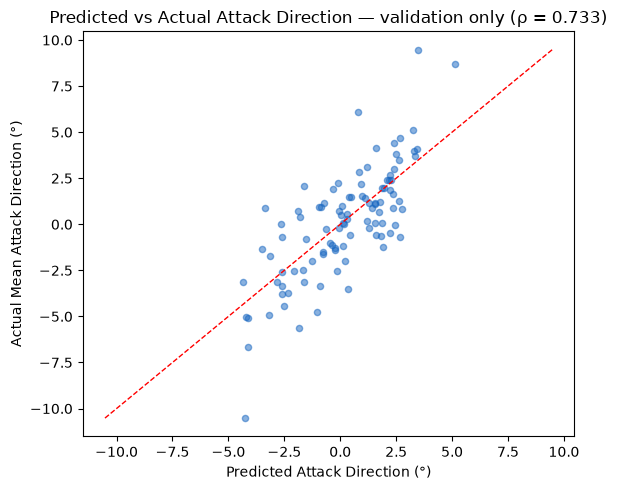

In [ ]:
mlb_corr["mean_actual_ad"] = (
    df_model_val_pred.groupby("batter")[TARGET].mean()
    .reindex(mlb_corr["batter"]).values
)

paired_ad = mlb_corr[["mean_pred", "mean_actual_ad"]].dropna()
r_p, _   = stats.pearsonr(paired_ad["mean_pred"], paired_ad["mean_actual_ad"])
r_s, p_s = spearmanr(paired_ad["mean_pred"], paired_ad["mean_actual_ad"])
print(f"\n{'Actual Attack Direction':<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(paired_ad["mean_pred"], paired_ad["mean_actual_ad"],
           color="#1565C0", alpha=0.5, s=20)
lims = [paired_ad.min().min(), paired_ad.max().max()]
ax.plot(lims, lims, "r--", linewidth=1)
ax.set_xlabel("Predicted Attack Direction (\u00b0)")
ax.set_ylabel("Actual Mean Attack Direction (\u00b0)")
ax.set_title(f"Predicted vs Actual Attack Direction \u2014 validation only (\u03c1 = {r_s:.3f})")
plt.tight_layout()
plt.show()


## 14. New Jersey Jackals — Correlation Analysis

In [ ]:
TEAM = "New Jersey Jackals"   # adjust if stored differently in your DB

jackals = batter_lb[
    (batter_lb["batter_team"] == TEAM) &
    (batter_lb["qualified"])
].copy().sort_values("attack_dir_pred", ascending=False).reset_index(drop=True)

print(f"Jackals qualified batters: {len(jackals)}")
print()
print(jackals[[
    "batter", "stand", "bbe",
    "attack_dir_pred", "pull_pct", "pull_air_pct", "mean_bearing_norm"
]].to_string(index=False))


Jackals qualified batters: 4

        batter stand  bbe  attack_dir_pred  pull_pct  pull_air_pct  mean_bearing_norm
    Ford, Ryan     L  182            6.476     0.434         0.203              7.693
 Acevedo, Luis     R  193            5.544     0.337         0.109              3.405
Cipion, Arbert     R  197            5.275     0.401         0.183              4.874
 Parks, Bryson     R  186            2.676     0.366         0.145              4.459


In [ ]:
corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = jackals[["attack_dir_pred", col]].dropna()
    if len(paired) < 5:
        print(f"{label:<25}  {'n<5':>10}")
        continue
    r_p, p_p = stats.pearsonr(paired["attack_dir_pred"], paired[col])
    r_s, p_s = spearmanr(paired["attack_dir_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")


Metric                      Pearson r    Spearman     p-value
--------------------------------------------------------------
Pull%                             n<5
PullAir%                          n<5
Mean Bearing (norm)               n<5


In [ ]:
fl_raw = fl_raw[fl_raw["bearing"].between(-45, 45)]

In [ ]:
rh = fl_raw[fl_raw["batter_side"].str.lower() == "right"]
lh = fl_raw[fl_raw["batter_side"].str.lower() == "left"]

print(rh["bearing"].describe())
print(lh["bearing"].describe())
print(f"\nRHH mean: {rh['bearing'].mean():.2f}°")
print(f"LHH mean: {lh['bearing'].mean():.2f}°")

count   35029.000
mean       -4.136
std        22.719
min       -44.993
25%       -22.352
50%        -6.338
75%        13.260
max        44.945
Name: bearing, dtype: float64
count   25653.000
mean        3.659
std        23.093
min       -44.952
25%       -14.464
50%         5.583
75%        22.671
max        44.995
Name: bearing, dtype: float64

RHH mean: -4.14°
LHH mean: 3.66°


<Axes: title={'center': 'RHH Mean EV by Bearing Bin'}, xlabel='bearing'>

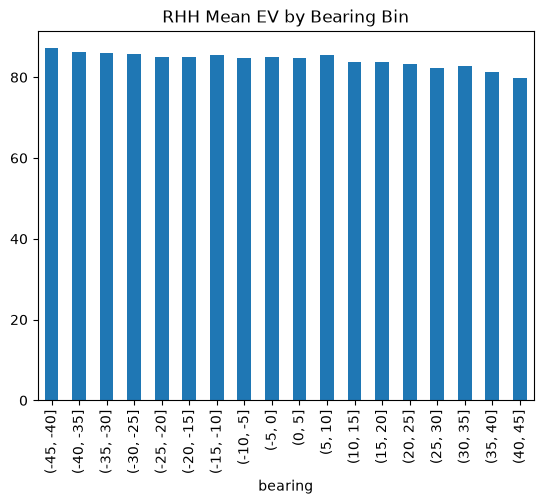

In [ ]:
rh = fl_raw[fl_raw["batter_side"].str.lower() == "right"]
rh.groupby(pd.cut(rh["bearing"], bins=np.arange(-45, 46, 5)))["exit_speed"].mean().plot(
    kind="bar", title="RHH Mean EV by Bearing Bin"
)

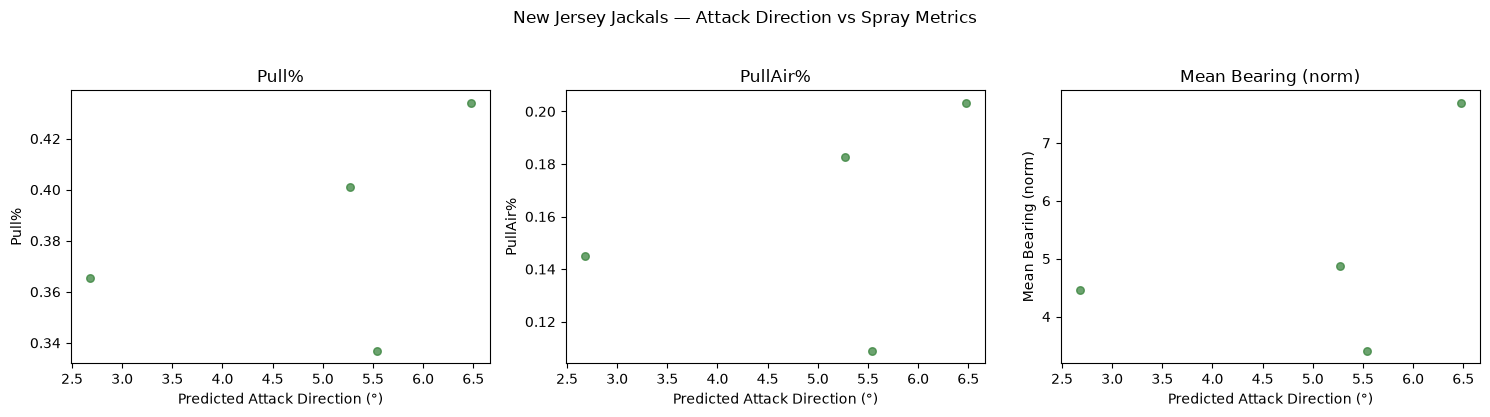

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, col) in zip(axes, corr_targets.items()):
    ax.scatter(jackals["attack_dir_pred"], jackals[col], color="#2E7D32", alpha=0.7, s=30)
    ax.set_xlabel("Predicted Attack Direction (\u00b0)")
    ax.set_ylabel(label)
    ax.set_title(label)
plt.suptitle(f"{TEAM} \u2014 Attack Direction vs Spray Metrics", y=1.03)
plt.tight_layout()
plt.show()


In [ ]:
print(f"\n{TEAM} \u2014 Attack Direction Leaderboard")
print(jackals[[
    "batter_name", "stand", "bbe",
    "attack_dir_pred", "pull_pct", "pull_air_pct"
]].rename(columns={
    "batter_name":     "Batter",
    "stand":           "Side",
    "bbe":             "BBE",
    "attack_dir_pred": "AttackDir\u00b0",
    "pull_pct":        "Pull%",
    "pull_air_pct":    "PullAir%",
}).to_string(index=False) if "batter_name" in jackals.columns else
"batter_name column not present \u2014 join in name lookup before printing.")

out = OUTPUT_DIR / "attack_direction_fl_leaderboard.csv"
batter_lb.to_csv(out, index=False)
print(f"\nFull leaderboard saved \u2192 {out}")



New Jersey Jackals — Attack Direction Leaderboard
batter_name column not present — join in name lookup before printing.

Full leaderboard saved → output\attack_direction_fl_leaderboard.csv


In [ ]:
from scipy import stats
from scipy.stats import spearmanr

fl_corr = batter_lb[batter_lb["qualified"]].copy()

corr_targets = {
    "Pull%":               "pull_pct",
    "PullAir%":            "pull_air_pct",
    "Mean Bearing (norm)": "mean_bearing_norm",
}

print(f"FL correlations (batter level, ≥{MIN_BBE} BBE, n={len(fl_corr)})")
print(f"{'Metric':<25}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 62)
for label, col in corr_targets.items():
    paired = fl_corr[["attack_dir_pred", col]].dropna()
    if len(paired) < 5:
        print(f"{label:<25}  {'n<5':>10}")
        continue
    r_p, _   = stats.pearsonr(paired["attack_dir_pred"], paired[col])
    r_s, p_s = spearmanr(paired["attack_dir_pred"], paired[col])
    print(f"{label:<25}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")

FL correlations (batter level, ≥150 BBE, n=121)
Metric                      Pearson r  Spearman ρ     p-value
--------------------------------------------------------------
Pull%                          0.3042      0.2672    3.05e-03
PullAir%                       0.0351      0.0427    6.42e-01
Mean Bearing (norm)            0.3640      0.3182    3.75e-04
